# Week 4 – Predictive Modeling and Optimization in Logistics Systems

**Yuva Intern | Logistics Data Analyst Project**

## Problem definition
Predict actual delivery duration (hours) for shipments that are delivered, using information available at dispatch: planned distance, shipment weight, carrier, service type, region, warehouse, and order calendar features.

The dataset is the same 600-row synthetic logistics dataset used in Weeks 1–3. Because a delivery duration requires a delivered timestamp, only delivered records with a positive, valid duration are included in supervised model training. The target is calculated as `delivered_time - dispatch_time`.

**Important:** The data is synthetic and for educational demonstration only. Predictions must not be treated as real operational forecasts.

## 1. Install/import libraries and load data

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [15]:
file_path = "logistics_shipments_synthetic_week4.csv"
if not os.path.exists(file_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Place logistics_shipments_synthetic.csv in the notebook folder.")
raw = pd.read_csv(file_path)
print("Raw dataset shape:", raw.shape)
display(raw.head())


Raw dataset shape: (600, 14)


,order_id,shipment_id,order_date,warehouse,region,carrier,service_type,planned_distance_km,shipment_weight_kg,dispatch_time,promised_delivery_time,delivered_time,status,actual_cost_inr
0,ORD-0000,SHP-0000,2026-07-08,WH-02,West,Carrier A,Express,127.3,5.1,2026-07-08 10:00:00,2026-07-08 13:08:07.574840772,2026-07-08 13:08:07.574840772,Delivered,240.83
1,ORD-0001,SHP-0001,2026-08-24,WH-03,East,Carrier A,Express,170.0,8.9,2026-08-24 09:00:00,2026-08-24 12:53:23.199370789,NaN,Failed Attempt,368.73
2,ORD-0002,SHP-0002,2026-09-08,WH-03,South,Carrier A,Standard,112.6,12.3,2026-09-08 06:00:00,2026-09-08 07:39:20.290695955,2026-09-08 07:56:52.106701124,Delivered,224.95
3,ORD-0003,SHP-0003,2026-07-25,WH-01,North,Carrier C,Express,101.4,7.5,2026-07-25 17:00:00,2026-07-25 23:07:39.854973989,2026-07-25 21:32:20.633314066,Delivered,187.73
4,ORD-0004,SHP-0004,2026-07-22,WH-02,South,Carrier B,Standard,183.9,6.2,2026-07-22 02:00:00,2026-07-22 07:03:28.988774820,2026-07-22 06:23:53.903282452,Delivered,325.81


## 2. Prepare target and features

In [16]:
data = raw.copy()
for col in ["order_date", "dispatch_time", "delivered_time"]:
    data[col] = pd.to_datetime(data[col], errors="coerce")

data["delivery_time_hours"] = (
    data["delivered_time"] - data["dispatch_time"]
).dt.total_seconds() / 3600

# Supervised target is available only for completed deliveries.
model_data = data[
    data["status"].eq("Delivered") &
    data["delivery_time_hours"].gt(0) &
    data["delivery_time_hours"].notna()
].copy()

model_data["order_month"] = model_data["order_date"].dt.month
model_data["order_dayofweek"] = model_data["order_date"].dt.dayofweek

features = [
    "planned_distance_km", "shipment_weight_kg", "carrier", "service_type",
    "region", "warehouse", "order_month", "order_dayofweek"
]
target = "delivery_time_hours"
X = model_data[features]
y = model_data[target]
print("Modeling rows:", len(model_data))
print("Target summary:")
display(y.describe().to_frame("delivery_time_hours"))


Modeling rows: 543
Target summary:


,delivery_time_hours
count,543.000000
mean,4.624414
std,2.239036
min,1.000000
25%,3.093638
50%,4.153346
75%,6.024659
max,13.508811


## 3. Train/test split and preprocessing

An 80/20 train/test split with `random_state=42` is used for reproducibility. Numeric fields are median-imputed and standardized. Categorical fields are most-frequent imputed and one-hot encoded. Preprocessing is placed inside Scikit-learn pipelines so transformations are learned from training data only, reducing data leakage.

In [17]:
numeric_features = ["planned_distance_km", "shipment_weight_kg", "order_month", "order_dayofweek"]
categorical_features = ["carrier", "service_type", "region", "warehouse"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))


Training rows: 434 | Test rows: 109


## 4. Train candidate models

In [18]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])
random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2, random_state=42, n_jobs=-1
    ))
])

linear_model.fit(X_train, y_train)
random_forest.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)
pred_rf = random_forest.predict(X_test)


## 5. Evaluate models

In [19]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

baseline_pred = np.repeat(y_train.mean(), len(y_test))
results = pd.DataFrame([
    {"Model": "Mean baseline", **evaluate(y_test, baseline_pred)},
    {"Model": "Linear Regression", **evaluate(y_test, pred_linear)},
    {"Model": "Random Forest (default)", **evaluate(y_test, pred_rf)}
])
display(results.round(3))


,Model,MAE,RMSE,R2
0,Mean baseline,1.857,2.256,-0.007
1,Linear Regression,1.244,1.666,0.451
2,Random Forest (default),1.360,1.724,0.412


## 6. Cross-validation and hyperparameter tuning

Five-fold cross-validation and a small grid search are applied to the Random Forest pipeline using training data only. The held-out test set remains untouched until final evaluation. Tuning is not assumed to improve performance; candidate models must be compared on the same test set.

In [20]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    param_grid={
        "model__n_estimators": [150, 250],
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [1, 2]
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)
grid.fit(X_train, y_train)
best_rf = grid.best_estimator_
pred_tuned_rf = best_rf.predict(X_test)
print("Best parameters:", grid.best_params_)
print("Mean CV MAE (hours):", -grid.best_score_)
print("Tuned Random Forest test metrics:", evaluate(y_test, pred_tuned_rf))


Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 150}
Mean CV MAE (hours): 1.3044443257170444
Tuned Random Forest test metrics: {'MAE': 1.3513879288149173, 'RMSE': 1.7267963227752279, 'R2': 0.4098420719318827}


## 7. Final model comparison and selection

In [21]:
final_results = pd.DataFrame([
    {"Model": "Mean baseline", **evaluate(y_test, baseline_pred)},
    {"Model": "Linear Regression", **evaluate(y_test, pred_linear)},
    {"Model": "Random Forest (default)", **evaluate(y_test, pred_rf)},
    {"Model": "Random Forest (tuned)", **evaluate(y_test, pred_tuned_rf)}
])
display(final_results.round(3))
# Select the model with the lowest test MAE for this demonstration.
model_predictions = {
    "Linear Regression": pred_linear,
    "Random Forest (default)": pred_rf,
    "Random Forest (tuned)": pred_tuned_rf
}
selected_name = min(model_predictions, key=lambda name: mean_absolute_error(y_test, model_predictions[name]))
selected_predictions = model_predictions[selected_name]
print("Selected model based on lowest test MAE:", selected_name)


,Model,MAE,RMSE,R2
0,Mean baseline,1.857,2.256,-0.007
1,Linear Regression,1.244,1.666,0.451
2,Random Forest (default),1.360,1.724,0.412
3,Random Forest (tuned),1.351,1.727,0.410


Selected model based on lowest test MAE: Linear Regression


## 8. Visualize evaluation and feature importance

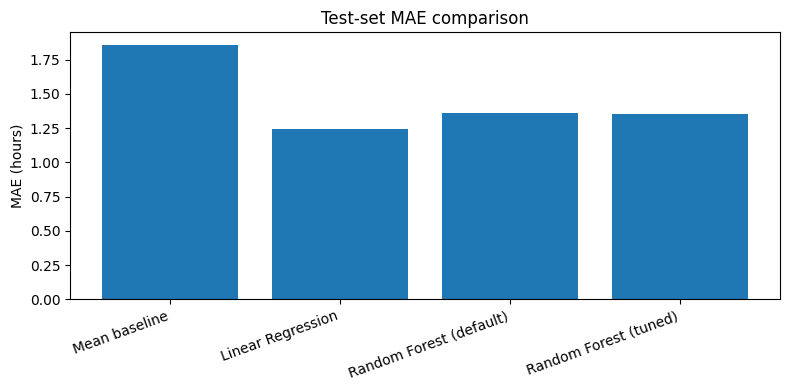

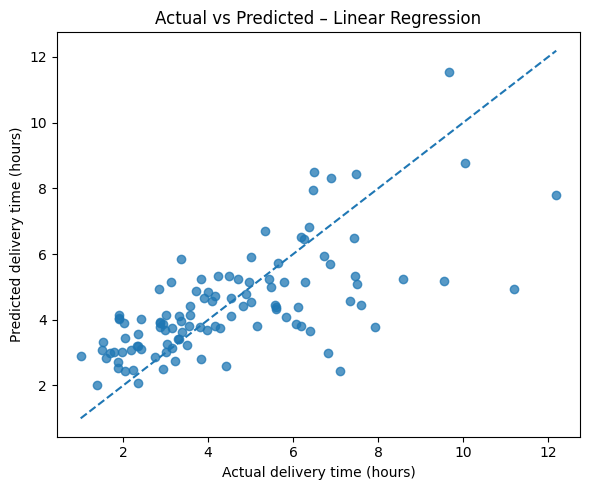

In [22]:
plt.figure(figsize=(8,4))
plt.bar(final_results["Model"], final_results["MAE"])
plt.title("Test-set MAE comparison")
plt.ylabel("MAE (hours)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
plt.scatter(y_test, selected_predictions, alpha=0.75)
low = min(y_test.min(), selected_predictions.min())
high = max(y_test.max(), selected_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual delivery time (hours)")
plt.ylabel("Predicted delivery time (hours)")
plt.title(f"Actual vs Predicted – {selected_name}")
plt.tight_layout()
plt.show()


In [23]:
# Random Forest feature importance is explanatory for that model, not a causal effect.
rf_preprocessor = best_rf.named_steps["preprocessor"]
rf_feature_names = rf_preprocessor.get_feature_names_out()
rf_importance = best_rf.named_steps["model"].feature_importances_
importance_table = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_importance
}).sort_values("importance", ascending=False)
display(importance_table.head(10))


,feature,importance
0,num__planned_distance_km,0.697278
1,num__shipment_weight_kg,0.089629
3,num__order_dayofweek,0.047998
2,num__order_month,0.035945
14,cat__region_West,0.013392
16,cat__warehouse_WH-02,0.012771
17,cat__warehouse_WH-03,0.011827
4,cat__carrier_Carrier A,0.010512
10,cat__region_Central,0.010394
8,cat__service_type_Same Day,0.009568


## 9. Optimization recommendations

In [24]:
print("Suggested operational actions based on the analysis:")
print("1. Use predicted delivery duration as a planning estimate, not a guaranteed promise.")
print("2. Review long-distance shipments early and allocate realistic delivery windows.")
print("3. Compare carrier performance on similar routes and service types before reallocating volume.")
print("4. Monitor prediction errors regularly and retrain only with validated new operational data.")
print("5. Test route or carrier changes as controlled pilots and compare cost, service and on-time outcomes.")


Suggested operational actions based on the analysis:
1. Use predicted delivery duration as a planning estimate, not a guaranteed promise.
2. Review long-distance shipments early and allocate realistic delivery windows.
3. Compare carrier performance on similar routes and service types before reallocating volume.
4. Monitor prediction errors regularly and retrain only with validated new operational data.
5. Test route or carrier changes as controlled pilots and compare cost, service and on-time outcomes.


## 10. Export results

In [25]:
output_dir = "week4_outputs"
os.makedirs(output_dir, exist_ok=True)
final_results.to_csv(os.path.join(output_dir, "week4_model_evaluation_metrics.csv"), index=False)
importance_table.head(10).to_csv(os.path.join(output_dir, "week4_feature_importance.csv"), index=False)
pd.DataFrame({
    "actual_delivery_time_hours": y_test.values,
    "selected_model_prediction_hours": selected_predictions,
    "absolute_error_hours": np.abs(y_test.values - selected_predictions)
}).to_csv(os.path.join(output_dir, "week4_test_predictions.csv"), index=False)
model_data.to_csv(os.path.join(output_dir, "week4_modeling_dataset.csv"), index=False)
print("Exported files:", os.listdir(output_dir))


Exported files: ['week4_model_evaluation_metrics.csv', 'week4_feature_importance.csv', 'week4_modeling_dataset.csv', 'week4_test_predictions.csv']


## 11. Conclusion and limitations

The notebook demonstrates a complete regression workflow: target construction, feature preparation, train/test split, preprocessing pipelines, candidate model training, evaluation, cross-validation, tuning, and recommendations. The dataset is synthetic and limited in size. A real deployment would require additional operational features, time-based validation, monitoring for data drift, and business review of model errors.